# Perturbation data overview (Fig. S4, Fig. S5)

UMAPs, control-cell overlays, per-perturbation panels, TF-expression heatmaps and pseudobulk heatmaps for the hESC TF-knockdown (CRISPRi, Virtual Cell Challenge 2025) and TF-overexpression (TFAtlas, GSE217460) subsets.

Run `perturb_knockdown.ipynb` and `perturb_overexpression.ipynb` first: they create `perturb/adata_kd.h5ad`, `perturb/adata_orf.h5ad` and `perturb/de_table_orf_gfp.csv`, which this notebook reads.

In [ ]:
import math

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scanpy as sc

In [2]:
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'DejaVu Sans'

In [56]:
adata = sc.read_h5ad("perturb/adata_kd.h5ad")
adata

.../site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 17179 × 17430
    obs: 'target_gene', 'guide_id', 'batch'

In [57]:
adata.layers["counts"] = adata.X.copy()

In [58]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

In [59]:
sc.pp.highly_variable_genes(adata, n_top_genes=1000)
sc.tl.pca(adata, svd_solver='arpack')
sc.pp.neighbors(adata)
sc.tl.umap(adata)

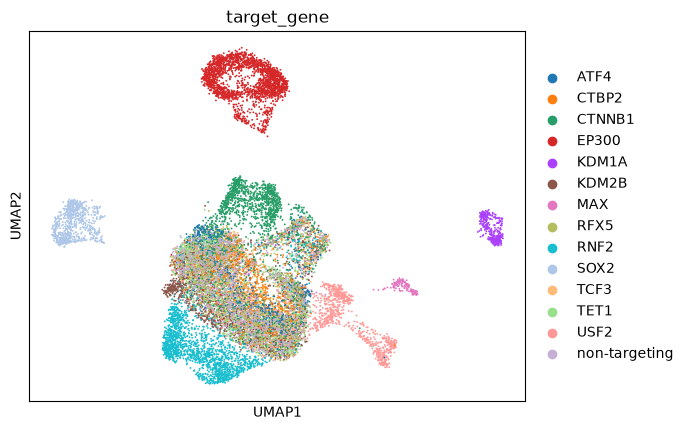

In [65]:
sc.pl.umap(
    adata,
    color='target_gene',
    # legend_loc="on data",
    show=False,
)
plt.savefig("perturb_kd_umap.pdf", bbox_inches='tight', dpi=300, transparent=True)

control_label
Other      16179
Control     1000
Name: count, dtype: int64


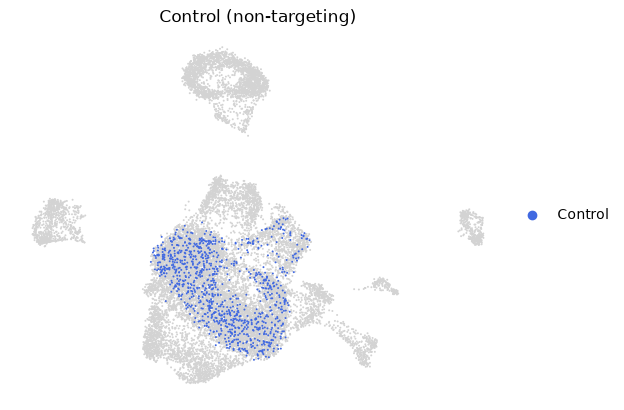

In [63]:
tf = adata.obs["target_gene"].astype(str)

# non-targeting -> "Control", everything else -> "Other"
lab = np.where(tf.str.lower() == "non-targeting", "Control", "Other")
adata.obs["control_label"] = pd.Categorical(lab, categories=["Other", "Control"])

print(adata.obs["control_label"].value_counts())   # sanity check

ax = sc.pl.umap(
    adata,
    color="control_label",
    groups=["Control"],
    palette={"Other": "lightgrey", "Control": "royalblue"},
    na_color="lightgrey",
    na_in_legend=False,
    title="Control (non-targeting)",
    frameon=False,
    size=8,
    show=False,
)
plt.savefig("perturb_kd_umap_controls.pdf", bbox_inches="tight", dpi=300, transparent=True)
plt.show()

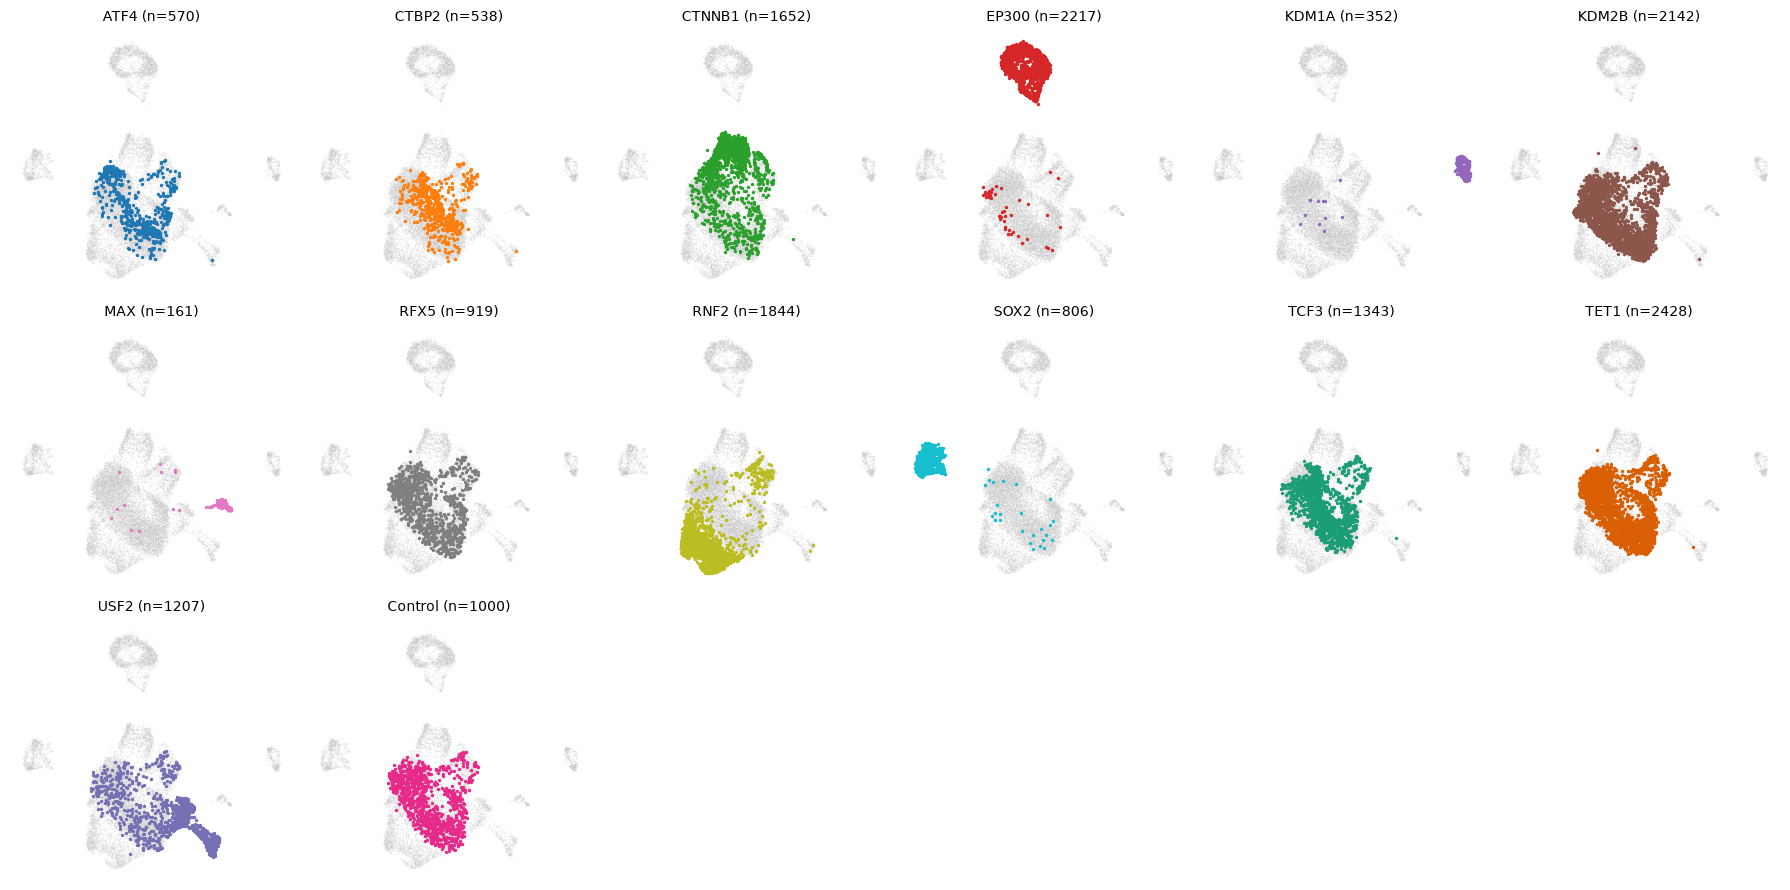

In [64]:
COL = "target_gene"
CONTROL = "non-targeting"

adata.obs[COL] = adata.obs[COL].astype("category")
cats = list(adata.obs[COL].cat.categories)

# control last
cats = [c for c in cats if c.lower() != CONTROL] + [c for c in cats if c.lower() == CONTROL]

# dark, saturated colours only (cycled if there are more groups than colours)
dark = (list(plt.get_cmap("tab20").colors[0::2])
        + list(plt.get_cmap("Dark2").colors)
        + list(plt.get_cmap("Set1").colors[:5]))
color_of = {c: dark[i % len(dark)] for i, c in enumerate(cats)}

# appearance settings
GREY, GREY_ALPHA, GREY_SIZE = "#c8c8c8", 0.25, 1
HI_SIZE = 6

xy = adata.obsm["X_umap"]
labels = adata.obs[COL].values

ncols = 6
nrows = math.ceil(len(cats) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
axes = np.atleast_1d(axes).flatten()

for ax, cat in zip(axes, cats):
    m = labels == cat
    ax.scatter(xy[~m, 0], xy[~m, 1], s=GREY_SIZE, c=GREY, alpha=GREY_ALPHA,
               linewidths=0, rasterized=True)
    ax.scatter(xy[m, 0], xy[m, 1], s=HI_SIZE, color=color_of[cat],
               linewidths=0, rasterized=True)
    title = "Control" if cat.lower() == CONTROL else cat
    ax.set_title(f"{title} (n={m.sum()})", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

# hide unused panels
for ax in axes[len(cats):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("perturb_kd_umap_split.pdf", bbox_inches="tight", dpi=300, transparent=True)
plt.show()

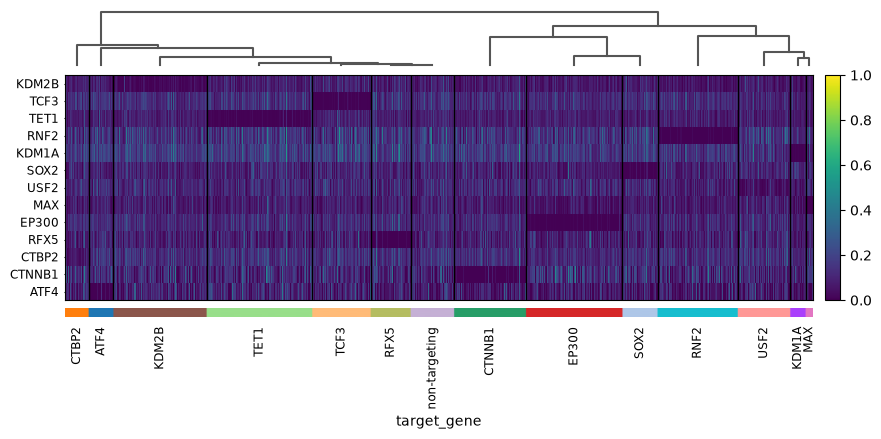

In [25]:
# Keep only genes present in the data (avoids KeyError)
genes = [g for g in adata.obs['target_gene'].unique() if g in adata.var_names]

# Basic heatmap: cells grouped by a categorical column (e.g. clusters)
sc.pl.heatmap(
    adata,
    var_names=genes,
    groupby="target_gene",        # any categorical column in adata.obs
    use_raw=False,           # set True if your normalized data is in adata.raw
    standard_scale="var",    # scale each gene 0–1 so genes are comparable
    cmap="viridis",              # any matplotlib colormap
    dendrogram=True,
    swap_axes=True,          # genes as rows, cells as columns
    figsize=(10, 4),
    show=False,
    # save="perturb_kd_heatmap.pdf"
)
plt.savefig("perturb_kd_heatmap.pdf", bbox_inches='tight', dpi=300, transparent=True)

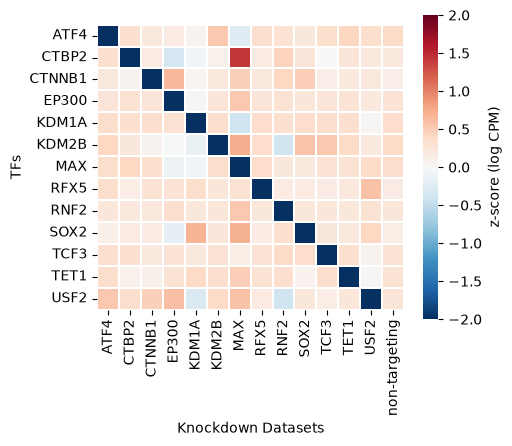

In [24]:
# Sum raw counts per perturbation (use your counts layer; layer=None uses adata.X)
pb = sc.get.aggregate(adata, by="target_gene", func="sum", layer="counts")
pb.X = pb.layers["sum"].copy()
sc.pp.normalize_total(pb, target_sum=1e6)   # CPM
sc.pp.log1p(pb)

# Genes x groups matrix, same order on both axes
groups = [g for g in pb.obs_names if g in pb.var_names]
mat = pb[:, groups].to_df().T          # rows = genes, columns = perturbations

# Z-score each gene across perturbations
mat_z = mat.sub(mat.mean(axis=1), axis=0).div(mat.std(axis=1), axis=0)

plt.figure(figsize=(0.15 * len(groups) + 3, 0.15 * len(groups) + 2))
sns.heatmap(mat_z, cmap="RdBu_r", center=0, vmin=-2, vmax=2, square=True,
            linewidths=0.3, cbar_kws={"label": "z-score (log CPM)"})
plt.xlabel("Knockdown Datasets")
plt.ylabel("TFs")
# plt.tight_layout()
plt.savefig("perturb_kd_pseudobulk_heatmap.pdf", bbox_inches="tight", dpi=300, transparent=True)

In [25]:
adata = sc.read_h5ad("perturb/adata_orf.h5ad")
adata

AnnData object with n_obs × n_vars = 36819 × 23413
    obs: 'TF', 'batch', 'louvain', 'n_counts', 'n_genes', 'percent_mito', 'batchTF', 'score', 'temp', 'dpt_pseudotime', 'm3_pseudotime'

In [26]:
adata.layers["counts"] = adata.X.copy()

In [27]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

In [28]:
sc.pp.highly_variable_genes(adata, n_top_genes=1000)
sc.tl.pca(adata, svd_solver='arpack')
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [31]:
adata.obs["TF_target"] = adata.obs["TF"].astype("category")

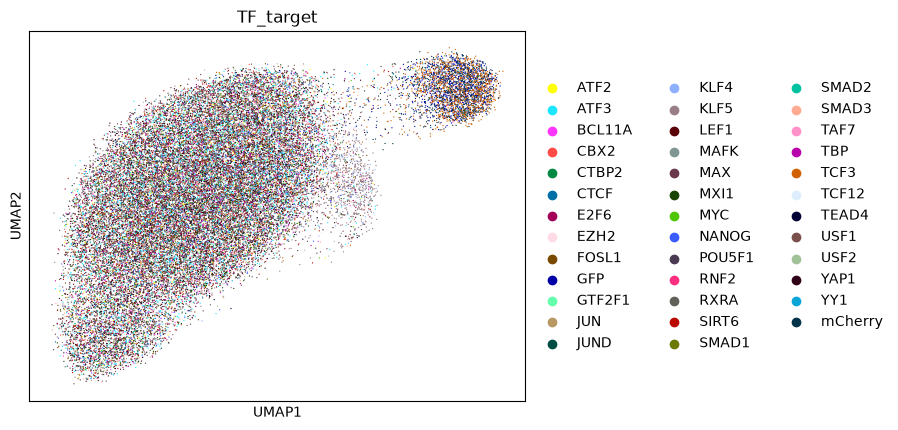

<Figure size 640x480 with 0 Axes>

In [32]:
sc.pl.umap(
    adata,
    color='TF_target',
    # legend_loc="on data",
    show=True,
)
plt.savefig("perturb_orf_umap.pdf", bbox_inches='tight', dpi=300, transparent=True)

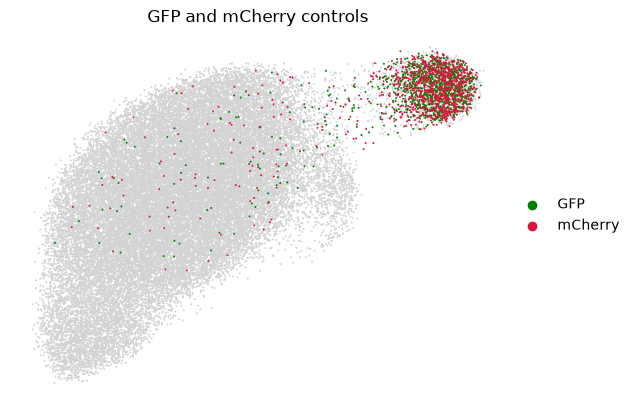

In [54]:
tf = adata.obs["TF_target"].astype(str)

# new column: GFP / mCherry / Other
lab = np.where(tf.str.lower() == "gfp", "GFP",
      np.where(tf.str.lower() == "mcherry", "mCherry", "Other"))
adata.obs["control_label"] = pd.Categorical(lab, categories=["Other", "GFP", "mCherry"])

ax = sc.pl.umap(
    adata,
    color="control_label",
    groups=["GFP", "mCherry"],     # these drawn on top; "Other" becomes NaN -> grey
    palette={"Other": "lightgrey", "GFP": "green", "mCherry": "crimson"},
    na_color="lightgrey",
    na_in_legend=False,
    title="GFP and mCherry controls",
    frameon=False,
    size=8,
    show=False,
)
plt.savefig("perturb_orf_umap_controls.pdf", bbox_inches="tight", dpi=300, transparent=True)
plt.show()

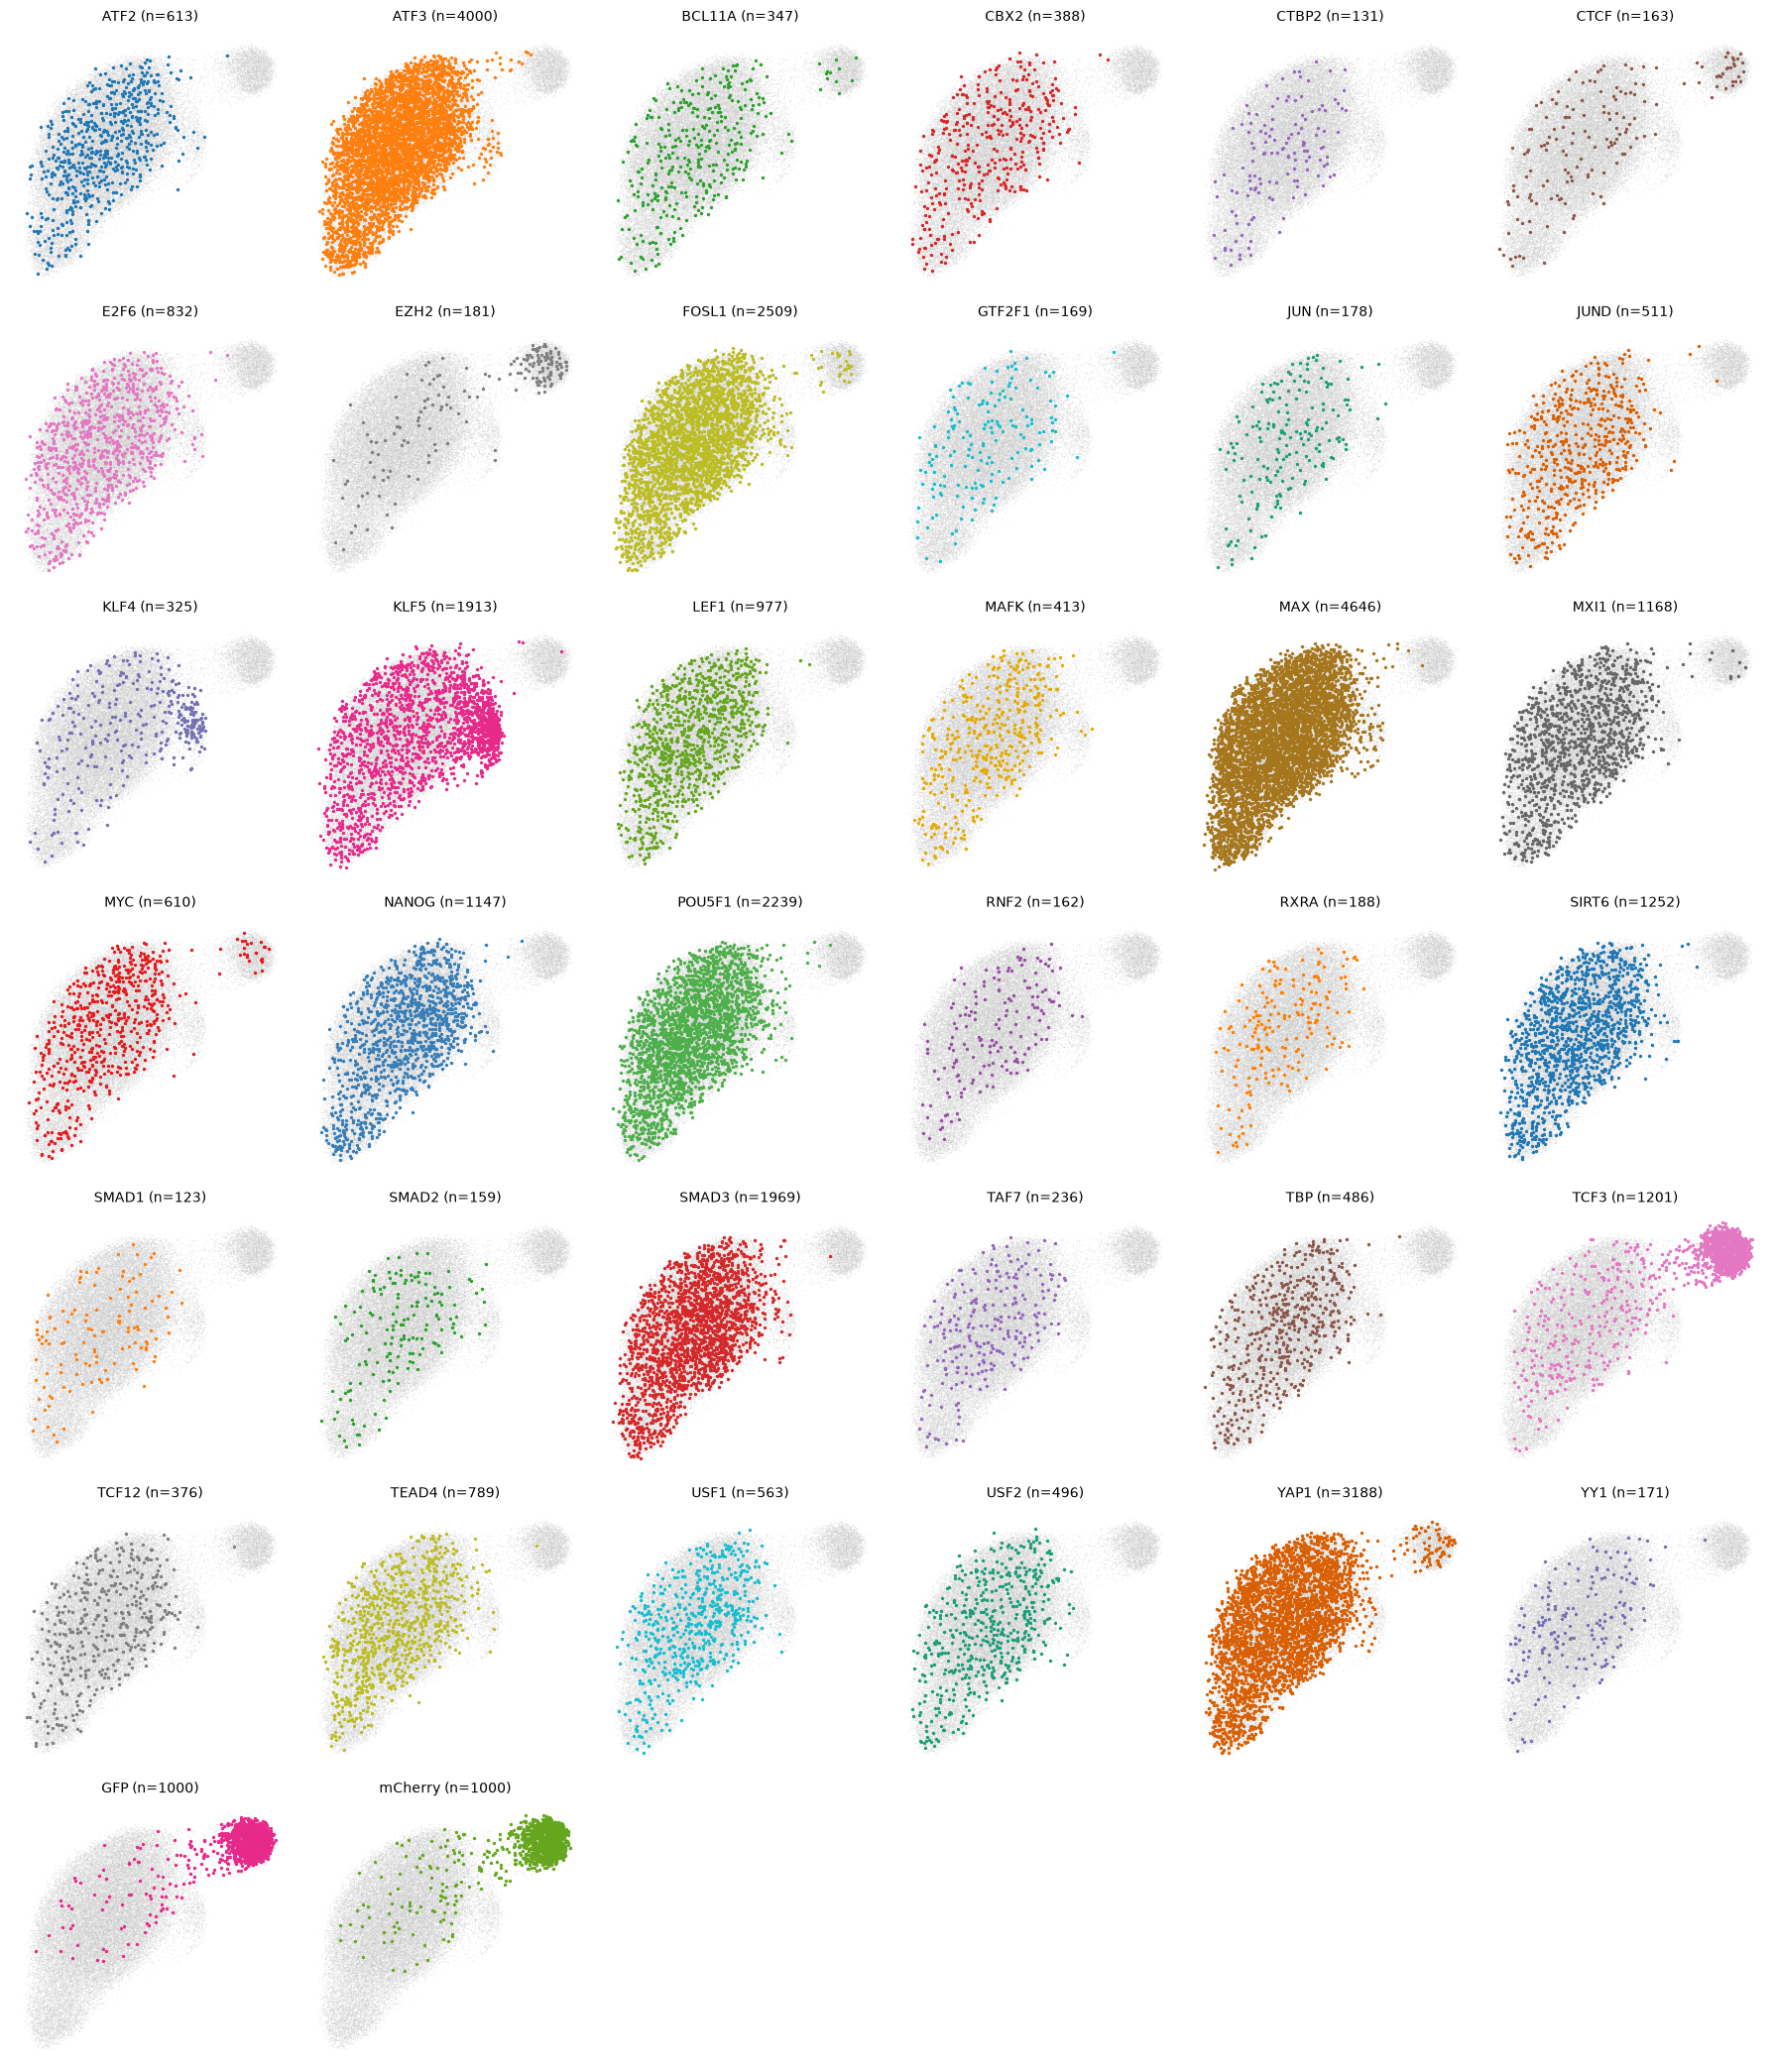

In [55]:
import math
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

adata.obs["TF_target"] = adata.obs["TF_target"].astype("category")
cats = list(adata.obs["TF_target"].cat.categories)

# controls last
controls = [c for c in cats if c.lower() in ("gfp", "mcherry")]
cats = [c for c in cats if c not in controls] + controls

# dark, saturated colours only (cycled if there are more groups than colours)
dark = (list(plt.get_cmap("tab20").colors[0::2])      # darker half of tab20
        + list(plt.get_cmap("Dark2").colors)
        + list(plt.get_cmap("Set1").colors[:5]))
color_of = {c: dark[i % len(dark)] for i, c in enumerate(cats)}

# appearance settings
GREY, GREY_ALPHA, GREY_SIZE = "#c8c8c8", 0.25, 1   # fainter background
HI_SIZE = 6                                         # highlighted dot size

xy = adata.obsm["X_umap"]
labels = adata.obs["TF_target"].values

ncols = 6
nrows = math.ceil(len(cats) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
axes = np.atleast_1d(axes).flatten()

for ax, cat in zip(axes, cats):
    m = labels == cat
    ax.scatter(xy[~m, 0], xy[~m, 1], s=GREY_SIZE, c=GREY, alpha=GREY_ALPHA,
               linewidths=0, rasterized=True)
    ax.scatter(xy[m, 0], xy[m, 1], s=HI_SIZE, color=color_of[cat],
               linewidths=0, rasterized=True)
    ax.set_title(f"{cat} (n={m.sum()})", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

# hide unused panels
for ax in axes[len(cats):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("perturb_orf_umap_split.pdf", bbox_inches="tight", dpi=300, transparent=True)
plt.show()

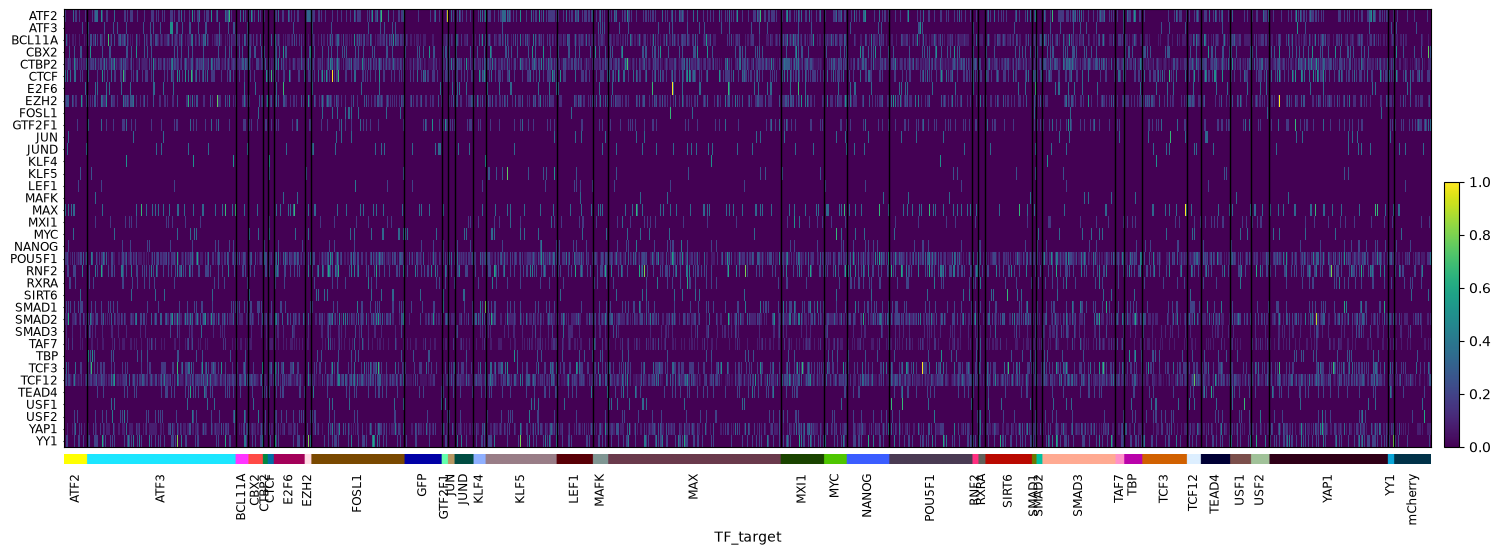

In [34]:
# Copy the obs column under a non-gene name
adata.obs["TF_target"] = adata.obs["TF"].astype("category")
genes = [g for g in adata.obs["TF_target"].cat.categories if g in adata.var_names]

sc.pl.heatmap(
    adata,
    var_names=genes,
    groupby="TF_target",
    use_raw=False,
    standard_scale="var",
    cmap="viridis",
    dendrogram=False,     # keep category order so knockdowns sit on the diagonal
    swap_axes=True,
    figsize=(18, 6),
    show=False,
    # save="perturb_kd_heatmap.pdf",
)
plt.savefig("perturb_orf_heatmap.pdf", bbox_inches='tight', dpi=300, transparent=True)

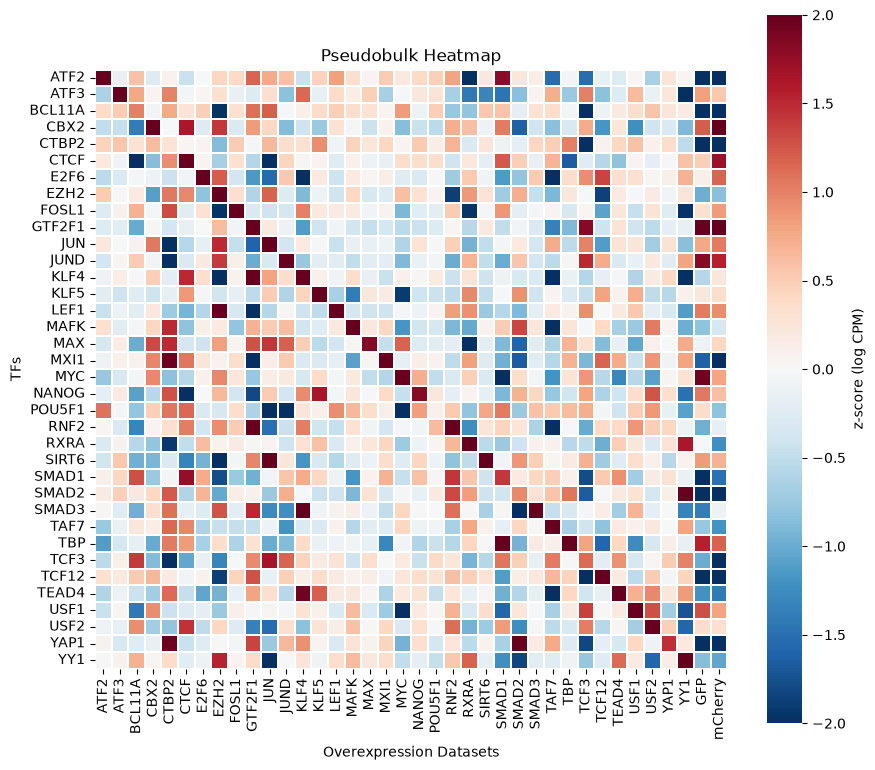

In [37]:
# Sum raw counts per perturbation (use your counts layer; layer=None uses adata.X)
pb = sc.get.aggregate(adata, by="TF_target", func="sum", layer="counts")
pb.X = pb.layers["sum"].copy()
sc.pp.normalize_total(pb, target_sum=1e6)   # CPM
sc.pp.log1p(pb)

# Genes x groups matrix, same order on both axes
groups = [g for g in pb.obs_names if g in pb.var_names]
mat = pb[:, groups].to_df().T          # rows = genes, columns = perturbations

# Z-score each gene across perturbations
mat_z = mat.sub(mat.mean(axis=1), axis=0).div(mat.std(axis=1), axis=0)
controls = [c for c in mat_z.columns if c.lower() in ("gfp", "mcherry")]
others = [c for c in mat_z.columns if c not in controls]
mat_z = mat_z[others + controls]

plt.figure(figsize=(0.20 * len(groups) + 3, 0.20 * len(groups) + 2))
sns.heatmap(mat_z, cmap="RdBu_r", center=0, vmin=-2, vmax=2, square=True,
            linewidths=0.3, cbar_kws={"label": "z-score (log CPM)"})
plt.xlabel("Overexpression Datasets")
plt.ylabel("TFs")
plt.title("Pseudobulk Heatmap")
# plt.tight_layout()
plt.savefig("perturb_orf_pseudobulk_heatmap.pdf", bbox_inches="tight", dpi=300, transparent=True)

In [66]:
de_table = pd.read_csv("perturb/de_table_orf_gfp.csv", index_col=0)
de_table

,names,scores,logfoldchanges,pvals,pvals_adj
group,,,,,
LEF1,GRID2,30.499426,1.011388,2.651988e-204,6.209099e-200
LEF1,NRXN1,19.417482,1.167448,5.491633e-84,8.571707e-81
LEF1,RIMS2,17.718540,1.062793,3.016431e-70,2.942655e-67
LEF1,CADM2,17.715742,0.944525,3.170197e-70,2.968953e-67
LEF1,RPSA,17.582884,1.460727,3.331896e-69,3.000372e-66
...,...,...,...,...,...
SMAD3,HMGN2,-27.142221,-2.112397,3.128148e-162,1.220656e-158
SMAD3,HMGA1,-28.620287,-1.284463,3.757670e-180,1.759567e-176
SMAD3,PTMA,-29.346317,-0.828143,2.662564e-189,1.558465e-185


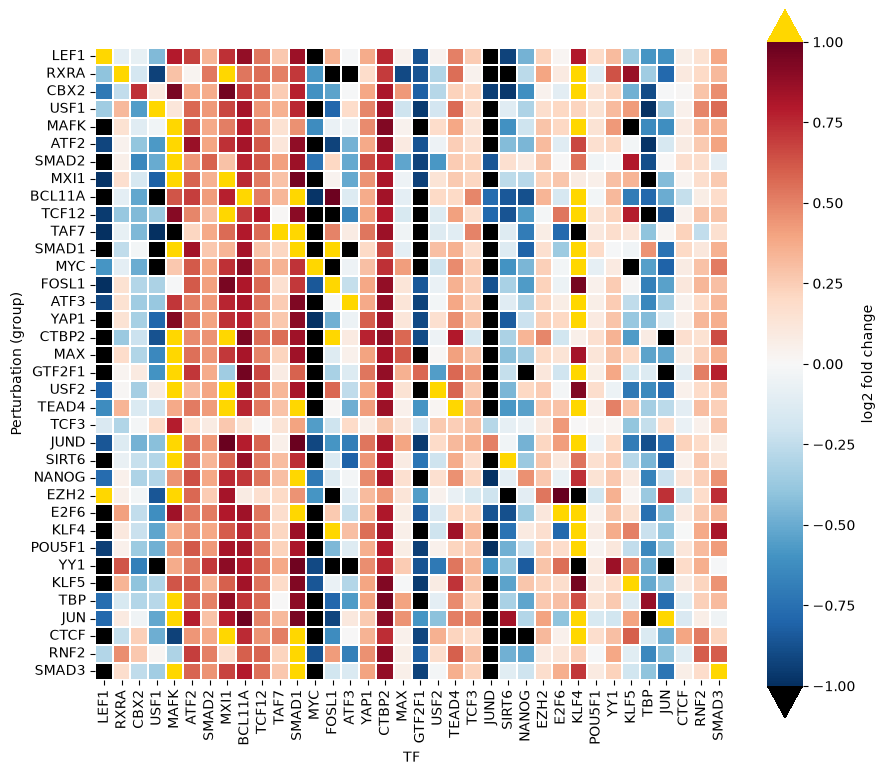

In [67]:
d = de_table.reset_index()          # turn the 'group' index into a column

groups = d["group"].unique()  # unique groups, in their original order

# keep only rows where the gene is one of the groups (e.g. the knocked-down TFs)
sub = d[d["names"].isin(groups)]

mat = sub.pivot_table(index="group", columns="names",
                      values="logfoldchanges", aggfunc="first")

# same order in rows and columns -> knockdown effect on the diagonal
order = [g for g in groups if g in mat.columns]
mat = mat.reindex(index=order, columns=order)

lim = abs(mat).max().max()    # symmetric colour scale centred on 0
plt.figure(figsize=(0.20 * len(order) + 3, 0.20 * len(order) + 2))
# sns.heatmap(mat, cmap="RdBu_r", center=0, vmin=-lim, vmax=lim,
#             square=True, linewidths=0.3,
#             cbar_kws={"label": "log2 fold change"})
import matplotlib as mpl

cmap = mpl.colormaps["RdBu_r"].copy()
cmap.set_under("black")    # values < -5
cmap.set_over("gold")      # values > 5
cmap.set_bad("lightgrey")  # NaN (gene/group pair missing)

sns.heatmap(mat, cmap=cmap, center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3,
            cbar_kws={"label": "log2 fold change", "extend": "both"})
plt.xlabel("TF")
plt.ylabel("Perturbation (group)")
# plt.tight_layout()
plt.savefig("perturb_orf_gfp_heatmap.pdf", bbox_inches='tight', dpi=300, transparent=True)
plt.show()